In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_data = pd.read_csv('/content/drive/MyDrive/data.csv')
X = df_data.drop(columns=["id", "diagnosis", "Unnamed: 32"])

print("Dataset dimensions:", X.shape)
print("Missing values:", X.isna().sum().sum())
print("Duplicate observations:", X.duplicated().sum())

display(X.head())
display(X.describe())

X = X.dropna()

Dataset dimensions: (569, 30)
Missing values: 0
Duplicate observations: 0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


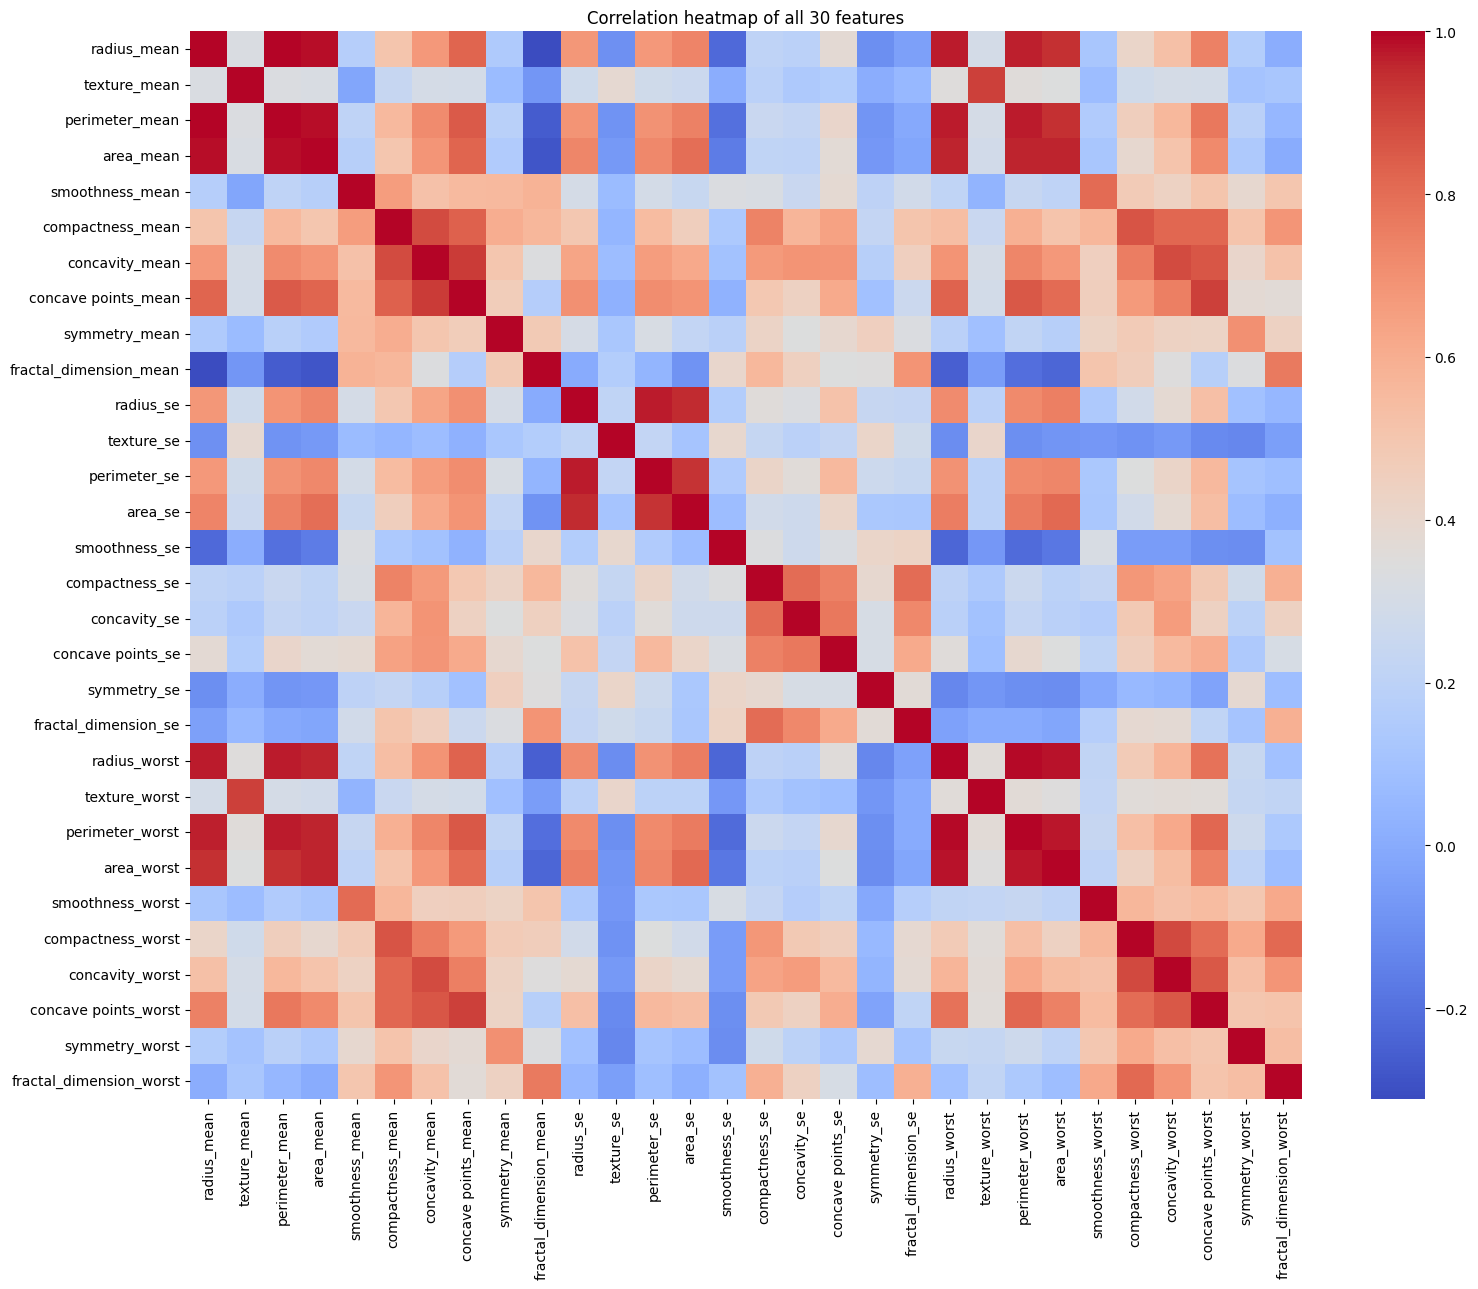

In [ ]:
plt.figure(figsize=(16, 13))

sns.heatmap(X.corr(), cmap="coolwarm")

plt.title("Correlation heatmap of all 30 features")
plt.tight_layout()
plt.show()

In [ ]:
#standardize to mean 0 and std dev 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("PC1:", pca.explained_variance_ratio_[0])
print("PC2:", pca.explained_variance_ratio_[1])
print("First two PCs:", pca.explained_variance_ratio_[:2].sum())

print("First six PCs:")
print(pca.explained_variance_ratio_[:6].sum())

PC1: 0.44272025607526366
PC2: 0.18971182044033078
First two PCs: 0.6324320765155944
First six PCs:
0.887587963566906


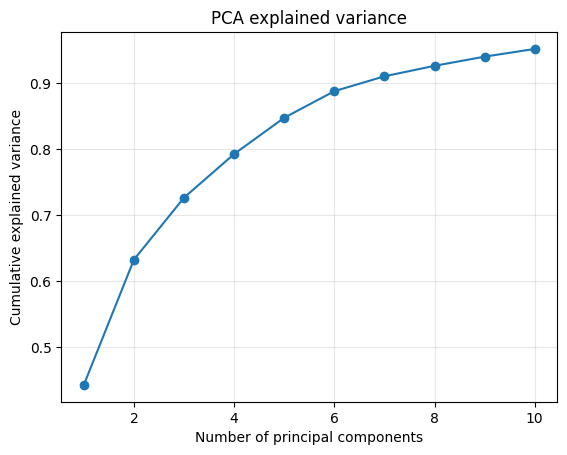

In [ ]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, 11),cumulative_variance[:10],marker="o")

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.grid(alpha=0.3)
plt.show()

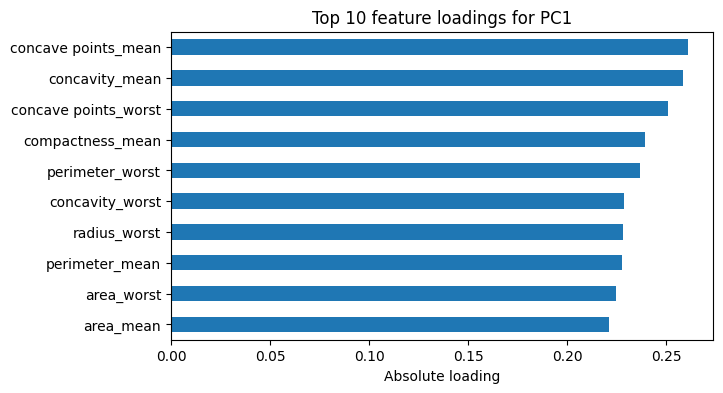

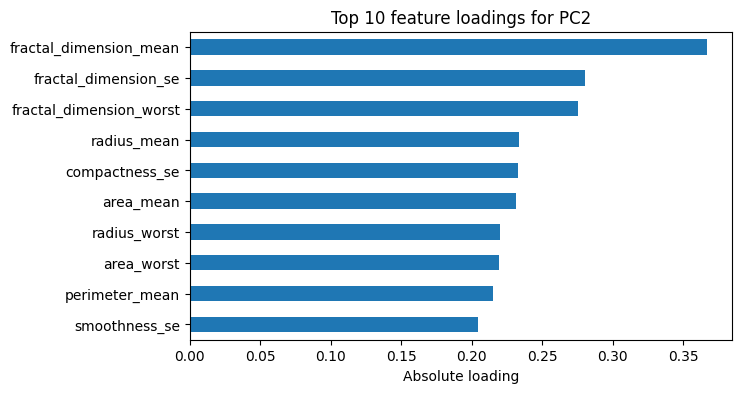

In [ ]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=[f"PC{i+1}" for i in range(pca.n_components_)])

for pc in ["PC1", "PC2"]:

    top_features = loadings[pc].abs().nlargest(10).sort_values()

    top_features.plot(kind="barh", figsize=(7, 4))

    plt.xlabel("Absolute loading")
    plt.title(f"Top 10 feature loadings for {pc}")
    plt.show()

In [ ]:
kmeans_results = []

for k in range(2, 7):

  model = KMeans(n_clusters=k, random_state=123, n_init=10 )

  labels = model.fit_predict(X_scaled)

  kmeans_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)})

kmeans_results = pd.DataFrame(kmeans_results)

display(kmeans_results)

,k,inertia,silhouette
0,2,11595.461474,0.344974
1,3,10061.797818,0.314384
2,4,9256.988836,0.279814
3,5,8554.941840,0.173058
4,6,7964.670760,0.161538


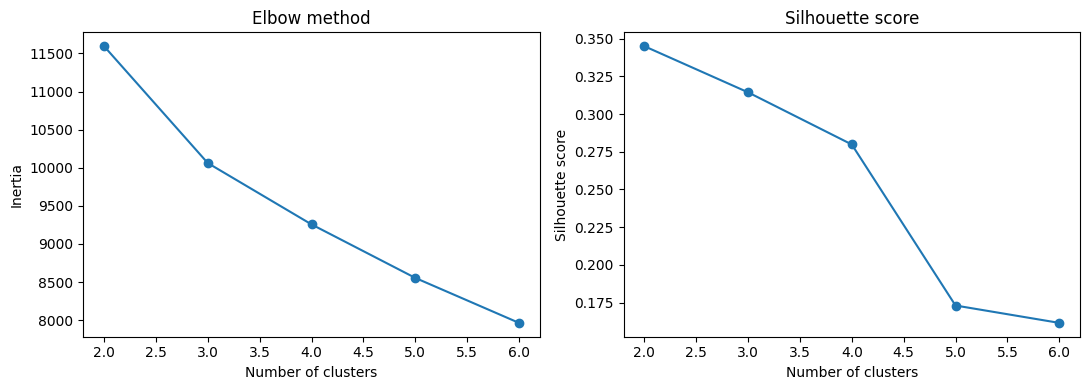

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    kmeans_results["k"],
    kmeans_results["inertia"],
    marker="o")

axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["silhouette"],
    marker="o")

axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

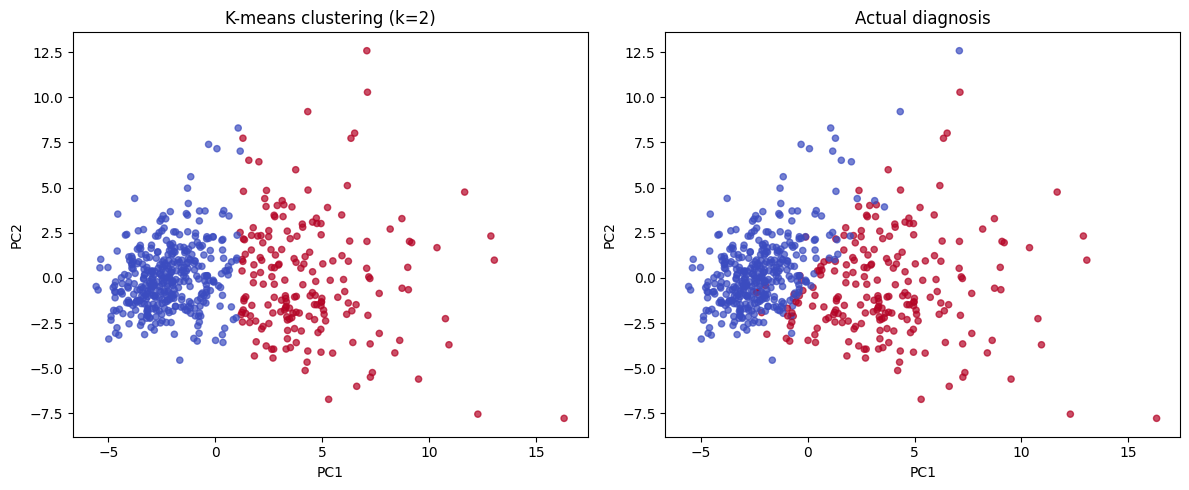

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=123, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#k-means clusters
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_kmeans, cmap="coolwarm", alpha=0.7, s=20, vmin=0, vmax=1)
axes[0].set_title("K-means clustering (k=2)")

#actual diagnosis
diagnosis = df_data.loc[X.index, "diagnosis"].map({"B": 0, "M": 1})

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=diagnosis, cmap="coolwarm", alpha=0.7, s=20, vmin=0, vmax=1)
axes[1].set_title("Actual diagnosis")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

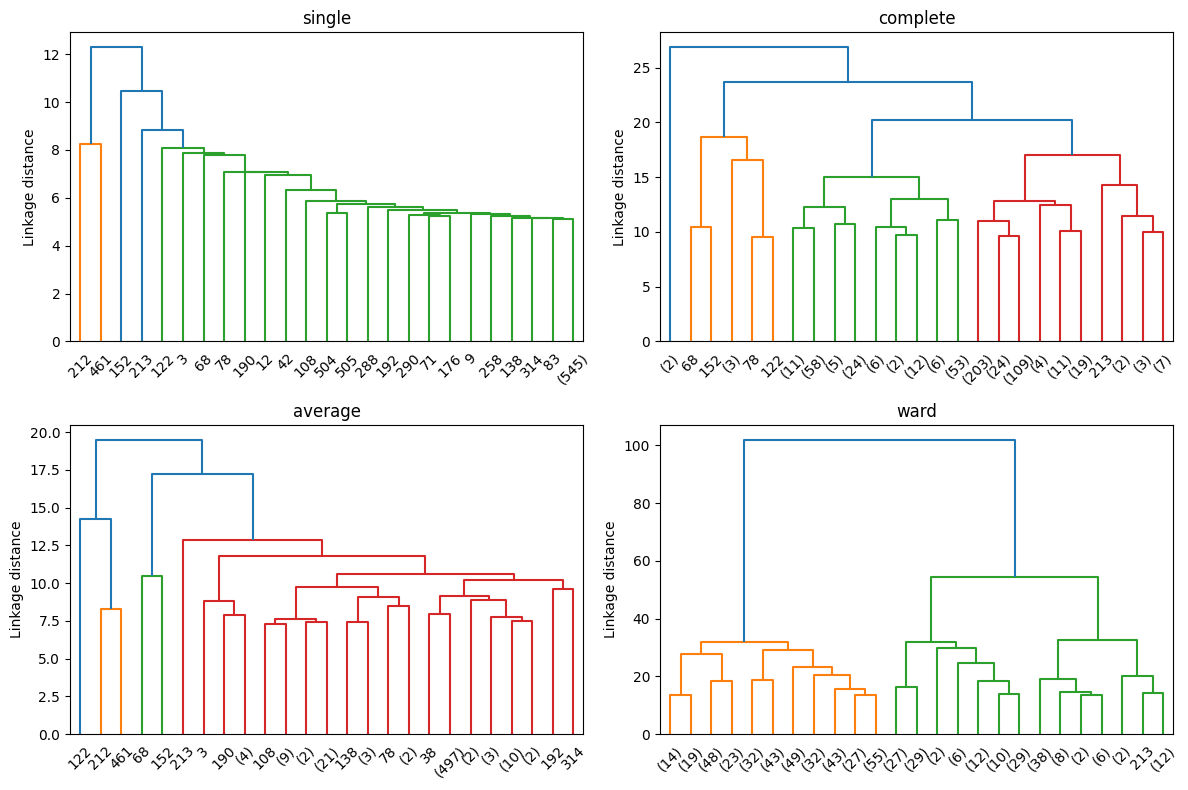

In [ ]:
methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, method in zip(axes.flat, methods):
    Z = linkage(X_scaled, method=method)

    dendrogram(Z, truncate_mode="lastp", p=25, ax=ax)
    ax.set_title(method)
    ax.set_ylabel("Linkage distance")

plt.tight_layout()
plt.show()

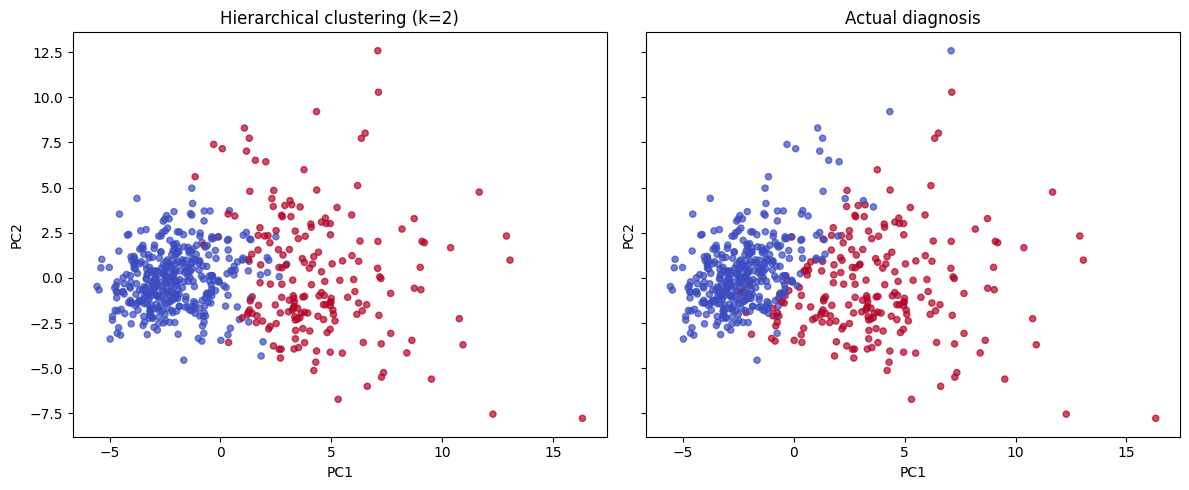

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

diagnosis = df_data.loc[X.index, "diagnosis"].map({"B": 0, "M": 1})

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_hier - 1, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7, s=20)
axes[0].set_title("Hierarchical clustering (k=2)")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=diagnosis, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7, s=20)
axes[1].set_title("Actual diagnosis")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [ ]:
agreement = adjusted_rand_score(
    clusters_kmeans,
    clusters_hier)

print("ARI between K-means and hierarchical clustering:", agreement)

ARI between K-means and hierarchical clustering: 0.8163668665187986


In [ ]:
diagnosis = df_data.loc[X.index, "diagnosis"].replace({0: "B", 1: "M"})

def compare_clusters(clusters):
    labels = pd.Series(clusters, index=X.index)
    mapping = pd.crosstab(labels, diagnosis).idxmax(axis=1)
    predicted = labels.map(mapping)

    return pd.crosstab(diagnosis, predicted).reindex(
        index=["B", "M"],
        columns=["B", "M"],
        fill_value=0)

summary = pd.DataFrame({
    ("Dataset", "Total"): [357, 212],
    ("K-means", "Benign"): [f"{km.loc['B', 'B']} (TN)", f"{km.loc['M', 'B']} (FN)"],
    ("K-means", "Malignant"): [f"{km.loc['B', 'M']} (FP)", f"{km.loc['M', 'M']} (TP)"],
    ("Hierarchical", "Benign"): [f"{hier.loc['B', 'B']} (TN)", f"{hier.loc['M', 'B']} (FN)"],
    ("Hierarchical", "Malignant"): [f"{hier.loc['B', 'M']} (FP)", f"{hier.loc['M', 'M']} (TP)"]
}, index=["Benign", "Malignant"])

summary.index.name = "Actual diagnosis"

display(summary)

Dataset   K-means           Hierarchical          
                   Total    Benign Malignant       Benign Malignant
Actual diagnosis                                                   
Benign               357  343 (TN)   14 (FP)     337 (TN)   20 (FP)
Malignant            212   37 (FN)  175 (TP)      48 (FN)  164 (TP)

In [ ]:
ari_kmeans = adjusted_rand_score(diagnosis, clusters_kmeans)

ari_hier = adjusted_rand_score(diagnosis,clusters_hier)

print("K-means ARI:", ari_kmeans)
print("Hierarchical ARI:", ari_hier)

K-means ARI: 0.6707206476880808
Hierarchical ARI: 0.5750409366326297


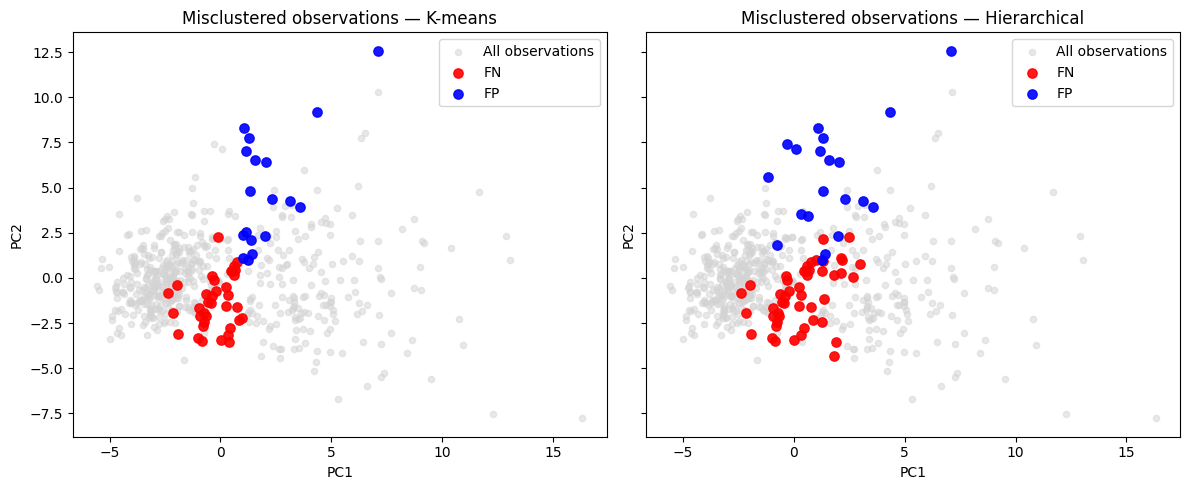

In [ ]:
dfig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, groups, method in zip(
    axes,
    [groups_kmeans, groups_hier],
    ["K-means", "Hierarchical"]):
    #all observations in grey
    ax.scatter(X_pca[:, 0], X_pca[:, 1], color="lightgray", alpha=0.5, s=20, label="All observations")

    #highlight false positives and false negatives
    for group, color in [("FN", "red"), ("FP", "blue")]:
        mask = (groups == group).to_numpy()

        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=color, label=group, s=45, alpha=0.9)

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"Misclustered observations — {method}")
    ax.legend()

plt.tight_layout()
plt.show()

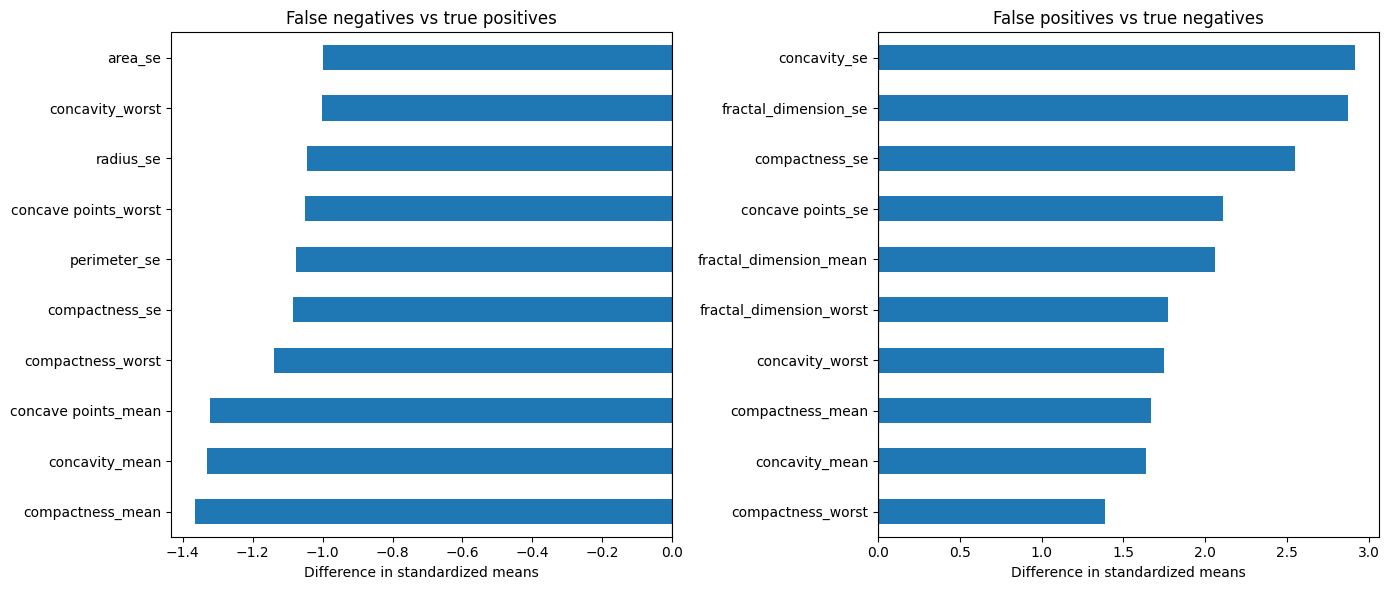

In [ ]:
fn_diff = group_means.loc["FN"] - group_means.loc["TP"]
fp_diff = group_means.loc["FP"] - group_means.loc["TN"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, diff, title in zip(
    axes,
    [fn_diff, fp_diff],
    ["False negatives vs true positives", "False positives vs true negatives"]):
    top = diff.reindex(diff.abs().nlargest(10).index).sort_values()

    top.plot(kind="barh", ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Difference in standardized means")
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [ ]:
#neural network autoencoder, see if it learns the same features

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(123)
np.random.seed(123)

X_train, X_val = train_test_split(X, test_size=0.2, random_state=123)

scaler_nn = StandardScaler()

X_train_nn = scaler_nn.fit_transform(X_train)
X_val_nn = scaler_nn.transform(X_val)

X_train_t = torch.tensor(X_train_nn, dtype=torch.float32)
X_val_t = torch.tensor(X_val_nn, dtype=torch.float32)

In [ ]:
class Autoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(30, 16),
            nn.Tanh(),
            nn.Linear(16, 3))

        self.decoder = nn.Sequential(
            nn.Linear(3, 16),
            nn.Tanh(),
            nn.Linear(16, 30))

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = Autoencoder()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=3, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=30, bias=True)
  )
)


In [ ]:
history_train = []
history_val = []

best_val = float("inf")
best_weights = None
patience = 20
wait = 0

for epoch in range(1000):

    model.train()

    optimizer.zero_grad()

    output = model(X_train_t)
    loss = F.mse_loss(output, X_train_t)

    loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        train_loss = F.mse_loss(model(X_train_t), X_train_t).item()
        val_loss = F.mse_loss(model(X_val_t), X_val_t).item()

    history_train.append(train_loss)
    history_val.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        break

model.load_state_dict(best_weights)

print("Epochs:", len(history_train))
print("Best validation MSE:", round(best_val, 4))

Epochs: 1000
Best validation MSE: 0.2597


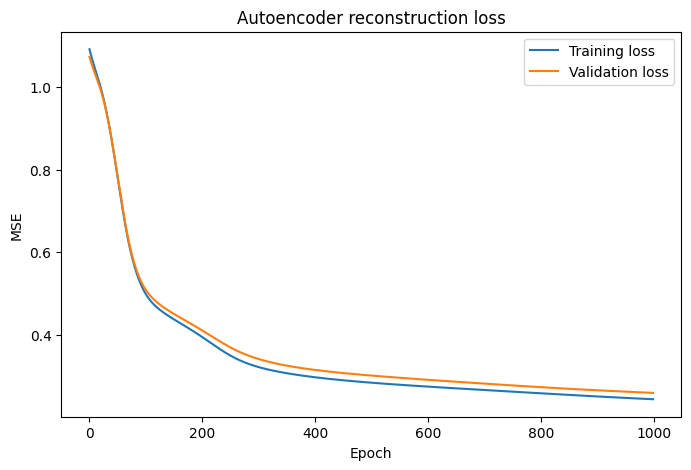

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_train, label="Training loss")
plt.plot(history_val, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder reconstruction loss")
plt.legend()
plt.show()

In [ ]:
pca_3 = PCA(n_components=3)

pca_3.fit(X_train_nn)

X_val_reconstructed = pca_3.inverse_transform(
    pca_3.transform(X_val_nn))

pca_mse = np.mean((X_val_nn - X_val_reconstructed)**2)

print("PCA validation MSE:", round(pca_mse, 4))
print("Autoencoder validation MSE:", round(best_val, 4))

PCA validation MSE: 0.2718
Autoencoder validation MSE: 0.2597


In [ ]:
model.eval()

X_all_nn = scaler_nn.transform(X)
X_all_t = torch.tensor(X_all_nn, dtype=torch.float32)

with torch.no_grad():
    X_latent = model.encoder(X_all_t).numpy()

X_latent = StandardScaler().fit_transform(X_latent)

kmeans_nn = KMeans(n_clusters=2, random_state=1, n_init=10)
clusters_nn = kmeans_nn.fit_predict(X_latent)

print("Cluster sizes:", np.bincount(clusters_nn))
print("Silhouette score:", round(silhouette_score(X_latent, clusters_nn), 3))

Cluster sizes: [206 363]
Silhouette score: 0.357


In [ ]:
print("Autoencoder vs K-means ARI:", round(adjusted_rand_score(clusters_nn, clusters_kmeans), 3))

Autoencoder vs K-means ARI: 0.591


In [ ]:
diagnosis = df_data.loc[X.index, "diagnosis"].replace({0: "B", 1: "M"})

print("Autoencoder vs diagnosis ARI:", round(adjusted_rand_score(diagnosis, clusters_nn), 3))

labels_nn = pd.Series(clusters_nn, index=X.index)

table_nn = pd.crosstab(labels_nn, diagnosis)

display(table_nn)

Autoencoder vs diagnosis ARI: 0.417


diagnosis,B,M
row_0,,
0,47,159
1,310,53
